In [1]:
import cftime
import xarray as xr
import numpy as np
import pandas as pd
import glob
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import time
#import numpy.ma as ma
#import composite_functions as cf
import scipy.stats as stats
#from read_sstdata_smiles import read_sstdata_smiles
#from sklearn.linear_model import LinearRegression
#from sklearn.metrics import r2_score
from tqdm import tqdm
import numpy.ma as ma
import sys
sys.path.append("/glade/work/smagahey/UCSB/codes/paper1_new/paper1/python_packages")
from myutils.composite_functions import select_events, var_composites

In [2]:
timesfut=["2070-01","2100-01"]
timespi=["1850-01","1880-01"]
tipast=["1850-01","2015-01"]
tissp=["2015-01","2100-01"]
n3=[-5,5,210,270] #Nino3
n34=[-5,5,190,240] # nino3.4?
n4=[-5,5,160,210]
pac=[-5,5,120,280]
regbox=[-80,80,90,300]
npmmbox=[10,30,245,285]
n12=[-10,0,270,280]

In [3]:
# Lat/lon regions to read in
ninobox=[-5,5,190,240]
latlon=[-90,90,0,360]

In [4]:
yrsfut=np.array(['2070','2071','2072','2073','2074','2075','2076','2077','2078','2079','2080','2081','2082','2083','2084','2085','2086','2087','2088','2089','2090','2091','2092','2093','2094','2095','2096','2097','2098','2099'])
yrshist=np.array(['1850','1851','1852','1853','1854','1855','1856','1857','1858','1859','1860','1861','1862','1863','1864','1865','1866','1867','1868','1869','1870','1871','1872','1873','1874','1875','1876','1877','1878','1879'])
yrshist=xr.DataArray(yrshist,dims=['time'])
yrsfut=xr.DataArray(yrsfut,dims=['time'])

In [5]:
mods370=['access_lens', 'canesm5_lens','cesm2_lens','ipsl_cm6a_lens','miroc6_lens','miroc_esm2l_lens'] #'cesm2_lens',
modsplus=['access_lens', 'canesm5_lens','cesm2_lens','ipsl_cm6a_lens','miroc_esm2l_lens','e3smv1_lens','e3smv2_lens']


In [6]:
ens_n34o=xr.open_dataset('/glade/work/smagahey/UCSB/codes/smile_data/tas_'+str(latlon[0])+'-'+str(latlon[1])+'N_'+str(latlon[2])+'-'+str(latlon[3])+'E_'+modsplus[0]+'_ssp370.nc')
    # Calculate NINO3.4 regional average
ens_n34v=ens_n34o['tas']
timecoords=ens_n34v.time

piEN=[]
piLN=[]
futEN=[]
futLN=[]

for m in tqdm(range(len(modsplus))): 
    print('mod=',modsplus[m])
    
    ens_n34o=xr.open_dataset('/glade/work/smagahey/UCSB/codes/smile_data/tas_'+str(latlon[0])+'-'+str(latlon[1])+'N_'+str(latlon[2])+'-'+str(latlon[3])+'E_'+modsplus[m]+'_ssp370.nc')
    # Calculate NINO3.4 regional average
    ens_tas=ens_n34o['tas'].convert_calendar('proleptic_gregorian',use_cftime=True)
    ens_tas=ens_tas.assign_coords({'time':timecoords})
    ens_tas=ens_tas - ens_tas.mean('member')
    taspi=ens_tas.sel(time=slice(timespi[0],timespi[1]))
    tasfut=ens_tas.sel(time=slice(timesfut[0],timesfut[1]))

    en_h,ln_h=select_events(taspi,n34,regbox,1850,1880,timespi)
    en_f,ln_f=select_events(tasfut,n34,regbox,2070,2100,timesfut)
    #taspd=ens_tas.sel(time=slice(timespd[0],timespd[1]))

    tosPI_en,tosPI_ln=var_composites(taspi,yrshist,en_h,ln_h,24)
    tosFUT_en,tosFUT_ln=var_composites(tasfut,yrsfut,en_f,ln_f,24)

    piEN.append(tosPI_en)
    piLN.append(tosPI_ln)
    futEN.append(tosFUT_en)
    futLN.append(tosFUT_ln)
    

In [7]:
n_subsample = 10
rng = np.random.default_rng(seed=42)  # fixed seed so it's reproducible

piEN=[]
piLN=[]
futEN=[]
futLN=[]

for m in tqdm(range(len(modsplus))): 
    print('mod=',modsplus[m])
    
    ens_n34o=xr.open_dataset('/glade/work/smagahey/UCSB/codes/smile_data/tas_'+str(latlon[0])+'-'+str(latlon[1])+'N_'+str(latlon[2])+'-'+str(latlon[3])+'E_'+modsplus[m]+'_ssp370.nc')
    # Calculate NINO3.4 regional average
    ens_tas=ens_n34o['tas'].convert_calendar('proleptic_gregorian',use_cftime=True)
    ens_tas=ens_tas.assign_coords({'time':timecoords})

    # --- subsample to n_subsample members ---
    n_members = ens_tas.sizes['member']
    if n_members < n_subsample:
        raise ValueError(f"{modsplus[m]} only has {n_members} members, fewer than {n_subsample}")
    chosen = rng.choice(n_members, size=n_subsample, replace=False)
    ens_tas = ens_tas.isel(member=chosen)
    print(f"  subsampled {n_members} -> {n_subsample} members")
    # -----------------------------------------

    ens_tas=ens_tas - ens_tas.mean('member')
    taspi=ens_tas.sel(time=slice(timespi[0],timespi[1]))
    tasfut=ens_tas.sel(time=slice(timesfut[0],timesfut[1]))

    en_h,ln_h=select_events(taspi,n34,regbox,1850,1880,timespi)
    en_f,ln_f=select_events(tasfut,n34,regbox,2070,2100,timesfut)

    tosPI_en,tosPI_ln=var_composites(taspi,yrshist,en_h,ln_h,24)
    tosFUT_en,tosFUT_ln=var_composites(tasfut,yrsfut,en_f,ln_f,24)

    piEN.append(tosPI_en)
    piLN.append(tosPI_ln)
    futEN.append(tosFUT_en)
    futLN.append(tosFUT_ln)

  0%|          | 0/7 [00:00<?, ?it/s]

mod= access_lens
  subsampled 40 -> 10 members


 14%|█▍        | 1/7 [00:08<00:48,  8.04s/it]

mod= canesm5_lens
  subsampled 50 -> 10 members


 29%|██▊       | 2/7 [00:16<00:41,  8.20s/it]

...

 71%|███████▏  | 5/7 [00:35<00:12,  6.46s/it]

mod= e3smv1_lens
  subsampled 15 -> 10 members


 86%|████████▌ | 6/7 [00:38<00:05,  5.42s/it]

mod= e3smv2_lens
  subsampled 10 -> 10 members


100%|██████████| 7/7 [00:41<00:00,  5.96s/it]


In [8]:
import scipy.stats as stats
def mannwhitney_vec(a, b):
    """
    Apply mannwhitneyu along the first dimension (members)
    for two 1D arrays.
    """
    from scipy.stats import mannwhitneyu
    stat, p = mannwhitneyu(a, b, alternative='two-sided')
    return p


In [9]:
def stipple_mask(pival,futval,alpha,x1,y1):
    
    pvals = xr.apply_ufunc(
    mannwhitney_vec,
    pival,futval,
    input_core_dims=[['member'], ['member']],
    vectorize=True,
    dask='parallelized',  # optional if using dask
    output_dtypes=[float],
    )
    
    sig = pvals < alpha

    x,y = np.meshgrid(x1, y1)
    x1_sig = x[sig.values]+180
    y1_sig = y[sig.values]
    
    return x1_sig, y1_sig

In [10]:
lags=[-9,-6]

In [11]:
capmods=['ACCESS-LENS','CanESM5-LENS','CESM2-LENS','IPSL-CM6A-LENS','MIROC-ESM2L-LENS','E3SMv1-LENS','E3SMv2-LENS']



In [12]:
def pool_group_members(piLN_list, futLN_list, indices, time_slice=(-10,-8)):
    pi_pool, fut_pool = [], []
    for idx in indices:
        pi_m = piLN_list[idx].sel(time=slice(*time_slice)).mean('time')
        fut_m = futLN_list[idx].sel(time=slice(*time_slice)).mean('time')

        # strip member coordinate labels if present, so concat doesn't choke
        if 'member' in pi_m.coords:
            pi_m = pi_m.reset_index('member', drop=True) if 'member' in pi_m.indexes else pi_m.drop_vars('member')
        if 'member' in fut_m.coords:
            fut_m = fut_m.reset_index('member', drop=True) if 'member' in fut_m.indexes else fut_m.drop_vars('member')

        pi_pool.append(pi_m)
        fut_pool.append(fut_m)
    return xr.concat(pi_pool, dim='member'), xr.concat(fut_pool, dim='member')

In [13]:
#e3sm_mods=['CanESM5-LENS','CESM2-LENS','E3SMv1-LENS','E3SMv2-LENS'] 
#non_e3sm_mods=['ACCESS-LENS','IPSL-CM6A-LENS','MIROC6-LENS','MIROC-ESM2L-LENS']

#G1=['ACCESS-LENS','CESM2-LENS','MIROC6-LENS','MIROC-ESM2L-LENS','E3SMv1-LENS']
#G2=['CanESM5-LENS','IPSL-CM6A-LENS','E3SMv2-LENS']
posmods=['IPSL-CM6A-LENS','MIROC-ESM2L-LENS','E3SMv2-LENS']
negmods=['ACCESS-LENS','CanESM5-LENS','CESM2-LENS','E3SMv1-LENS']
pos=[]
g1_ind=[3,4,6]
g2_ind=[0,1,2,5]

for i in g1_ind:
    #ax=fig.add_subplot(4,2,i+1,projection=ccrs.PlateCarree(central_longitude=180))
    #lonsig,latsig=stipple_mask(piEN[i].sel(time=-9),futEN[i].sel(time=-9),0.05,lon,lat)
    diffln=futLN[i] - piLN[i]
    print('doing model', modsplus[i])
    pos.append(diffln.mean('member'))
pos_skew=xr.concat(pos,dim='model')

doing model ipsl_cm6a_lens
doing model miroc_esm2l_lens
doing model e3smv2_lens


In [14]:
neg=[]
for j in g2_ind:
    #ax=fig.add_subplot(4,2,i+1,projection=ccrs.PlateCarree(central_longitude=180))
    #lonsig,latsig=stipple_mask(piEN[i].sel(time=-9),futEN[i].sel(time=-9),0.05,lon,lat)
    diffln=futLN[j] -piLN[j]
    print('doing model', modsplus[j])
    neg.append(diffln.mean('member'))
neg_skew=xr.concat(neg,dim='model')

doing model access_lens
doing model canesm5_lens
doing model cesm2_lens
doing model e3smv1_lens


In [15]:
# Run this after cell 13 (both g1_ind and g2_ind now exist)
lon=piLN[0].lon
lat=piLN[0].lat
pi_pool_pos, fut_pool_pos = pool_group_members(piLN, futLN, g1_ind)
pi_pool_neg, fut_pool_neg = pool_group_members(piLN, futLN, g2_ind)

lonsig_pos, latsig_pos = stipple_mask(pi_pool_pos, fut_pool_pos, 0.05, lon, lat)
lonsig_neg, latsig_neg = stipple_mask(pi_pool_neg, fut_pool_neg, 0.05, lon, lat)

In [16]:
pos_mam=pos_skew.sel(time=slice(-10,-8)).mean('time').mean('model')
neg_mam=neg_skew.sel(time=slice(-10,-8)).mean('time').mean('model')

In [17]:
import cartopy.feature as cfeature

NameError: name 'axes' is not defined

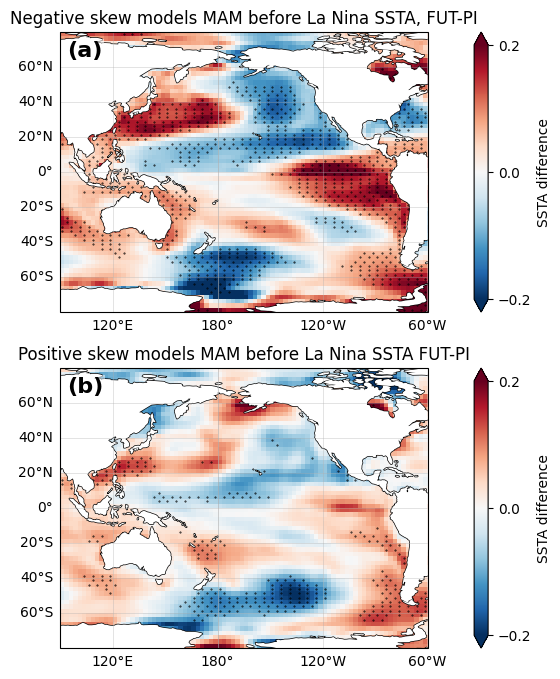

In [18]:
fig=plt.figure(figsize=(12,8))
vmi=-.2
vma=.2
lon=pos_mam.lon
lat=pos_mam.lat


                 

ax=fig.add_subplot(2,1,1,projection=ccrs.PlateCarree(central_longitude=180))
ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
im=ax.pcolormesh(lon,lat,neg_mam,transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
#ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
ax.scatter(lonsig_neg[::2],latsig_neg[::2],marker='.',s=.7,color='k')
ax.coastlines()
ax.add_feature(cfeature.LAND, facecolor='white', zorder=2) 
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
gl.top_labels   = False
gl.right_labels = False
ax.text(0.02, 0.97, '(a)', transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left',
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))
plt.title('Negative skew models MAM before La Nina SSTA, FUT-PI')
#cax = fig.add_axes([0.2, 0.13, 0.6, 0.03])  # [left, bottom, width, height]

cbar = fig.colorbar(
    im,
    orientation='vertical',
    extend='both'
)
cbar.set_label('SSTA difference')
cbar.set_ticks([vmi, 0, vma])

ax=fig.add_subplot(2,1,2,projection=ccrs.PlateCarree(central_longitude=180))
ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
im=ax.pcolormesh(lon,lat,pos_mam,transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
#ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=False,linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
ax.coastlines()
ax.scatter(lonsig_pos[::2],latsig_pos[::2],marker='.',s=.7,color='k')
ax.add_feature(cfeature.LAND, facecolor='white', zorder=2) 
ax.text(0.02, 0.97, '(b)', transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left',
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.5)
gl.top_labels   = False
gl.right_labels = False
plt.title('Positive skew models MAM before La Nina SSTA FUT-PI')
#cax = fig.add_axes([0.2, 0.13, 0.6, 0.03])  # [left, bottom, width, height]

cbar = fig.colorbar(
    im,
    orientation='vertical',
    extend='both'
)
cbar.set_label('SSTA difference')
cbar.set_ticks([vmi, 0, vma])

for ax, label in zip(axes, ['(a)', '(b)']):
    ax.text(0.02, 0.97, label, transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left',
            bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=1))




In [ ]:
allskew=xr.concat([pos_skew,neg_skew],dim='model')

In [ ]:
all_mam=allskew.sel(time=slice(-10,-8)).mean('time').mean('model')
fig=plt.figure(figsize=(10,8))
ax=fig.add_subplot(1,1,1,projection=ccrs.PlateCarree(central_longitude=180))

im=ax.pcolormesh(lon,lat,all_mam,transform = ccrs.PlateCarree(),cmap='RdBu_r',vmin=vmi,vmax=vma)
ax.coastlines()
ax.set_extent([regbox[2], regbox[3], regbox[0], regbox[1]], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor='white', zorder=2) 
plt.title('Multimodel mean MAM pre la Nina')

In [ ]:
all_mam